# Alpha Connectome: qué hay adentro de los datos

Recorrido por el dataset del challenge, de lo más simple (qué columnas hay) a lo más sutil (qué filas puntúan y cuánto pesan).

| | Sección | Pregunta |
|---|---|---|
| 1 | Los archivos | ¿Qué bajamos y cuánto pesa? |
| 2 | Primera mirada | ¿Cómo se ve una fila? |
| 3 | Las 112 variables | ¿Qué mide cada columna y qué valores trampa tiene? |
| 4 | Secuencias | ¿Cómo está organizado el tiempo? |
| 5 | Memoria | ¿Hasta dónde importa el pasado? ¿Por qué no se pueden mezclar filas? |
| 6 | Targets | ¿Qué forma tienen `t0` y `t1`? |
| 7 | Instrumentos | ¿Por qué hay 4 mercados adentro de los datos? |
| 8 | Correlación | ¿Qué variables se parecen y cuáles anticipan el target? |
| 9 | Métrica | ¿Qué filas puntúan y cuáles pesan? |
| 10 | Train vs. valid | ¿Son el mismo mercado? |

**Antes de correr:**
- Hacen falta `pandas`, `numpy`, `pyarrow` y `matplotlib`.
- `train.parquet` pesa 29 GB en disco y cerca de 100 GB en memoria, así que **nunca se carga entero**. Cada *row group* es una secuencia completa y se lee de a una.
- La primera corrida tarda unos 15 minutos. Los pasos lentos quedan en `cache/` y las siguientes tardan mucho menos. Borrá esa carpeta para recalcular todo.
- Cada figura va a `figuras/` y cada número del deck va a `resultados.json`.

In [1]:
from pathlib import Path
from statistics import NormalDist
import json, locale, sys, time, warnings

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from IPython.display import display

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40, 'display.width', 200, 'display.float_format', '{:.3f}'.format)

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datasets' / 'train.parquet').exists())
sys.path.insert(0, str(RAIZ))
from utils import FEATURE_COLUMNS as FEATURES  # las 112 columnas, en el orden oficial

FIG, CACHE = Path('figuras'), Path('cache')
FIG.mkdir(exist_ok=True)
CACHE.mkdir(exist_ok=True)

ARCHIVOS = {s: pq.ParquetFile(RAIZ / 'datasets' / f'{s}.parquet') for s in ['train', 'valid']}

SEED = 2026
N_POR_GRUPO = 25  # secuencias por split × instrumento en la muestra: 2 × 4 × 25 = 200
CENTINELA = -5.1993  # marca de "este dato no existe" (sección 3)
CUANTOS = np.array([0.12543, 0.24133, 0.46853, 0.65686])  # escalón del target por instrumento (sección 7)

R = {}  # todo lo que usa el deck termina acá y se guarda en resultados.json

# --- Estilo de los gráficos ----------------------------------------------------------------
TINTA, GRIS, GRILLA = '#101828', '#475467', '#E4E7EC'
AZUL, CORAL, TEAL, AMBAR = '#1D6FDC', '#E04F39', '#0E9384', '#E6A100'  # precios, volúmenes, trades, extras
INST = ['#9E8CF0', '#7A5AF8', '#5925DC', '#2D1A78']  # rampa ordinal: el tick crece del 0 al 3
COLOR_TIPO = {'Precios': AZUL, 'Volúmenes': CORAL, 'Trades': TEAL, 'Extras': AMBAR}
DIVERGENTE = LinearSegmentedColormap.from_list('div', [AZUL, '#F2F1EE', CORAL])
SECUENCIAL = LinearSegmentedColormap.from_list('sec', ['#F4F1FF', '#9E8CF0', '#5925DC', '#2D1A78'])

plt.rcParams.update({
    'font.family': ['Calibri', 'Arial', 'DejaVu Sans'], 'font.size': 12, 'figure.dpi': 90,
    'text.color': TINTA, 'axes.labelcolor': GRIS, 'xtick.color': GRIS, 'ytick.color': GRIS,
    'axes.edgecolor': '#98A2B3', 'axes.linewidth': .7, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': .6, 'axes.axisbelow': True,
    'axes.titlesize': 12.5, 'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
    'xtick.major.size': 0, 'ytick.major.size': 0, 'legend.frameon': False,
})
try:  # decimales con coma en los ejes, si el sistema tiene el idioma
    locale.setlocale(locale.LC_NUMERIC, 'es_ES.UTF-8')
    plt.rcParams['axes.formatter.use_locale'] = True
except locale.Error:
    pass


def leer(split, rg, columnas=None):
    """Una secuencia completa (un row group) como DataFrame."""
    return ARCHIVOS[split].read_row_group(int(rg), columns=columnas).to_pandas()


def familia(col):
    """i0_p13 → 'i0_p' · i1_dv2 → 'i1_dv' · a5 → 'a' · t0 → 't0'"""
    if col[0] == 'i':
        return col[:3] + col[3:].rstrip('0123456789')
    return 'a' if col[0] == 'a' else col


def tipo(col):
    """Agrupación gruesa: Precios, Volúmenes, Trades, Extras."""
    f = familia(col)
    if f == 'a':
        return 'Extras'
    if f[0] == 't':
        return f
    return {'p': 'Precios', 'v': 'Volúmenes', 'dp': 'Trades', 'dv': 'Trades'}[f[3:]]


def guardar(fig, nombre):
    fig.savefig(FIG / f'{nombre}.png', dpi=220, bbox_inches='tight', facecolor='white')
    plt.show()


def wp_global(y, p):
    """Weighted Pearson de la métrica vigente: una sola correlación con todas las filas, peso |y|."""
    y, p = np.clip(y, -2, 2).astype(float), np.clip(p, -2, 2).astype(float)
    w = np.abs(y)
    W = w.sum()
    my, mp = (w * y).sum() / W, (w * p).sum() / W
    cov = (w * (y - my) * (p - mp)).sum() / W
    return cov / np.sqrt((w * (y - my) ** 2).sum() / W * (w * (p - mp) ** 2).sum() / W)


print('Datos en', RAIZ / 'datasets')

Datos en C:\Users\Joaquin\Desktop\UM\semestre 8\Machine learning\proyecto final\wnn_connectome_starterpack\wnn_connectome_starterpack\datasets


## 1. Los archivos

Parquet guarda los metadatos aparte, así que podemos ver filas, columnas y row groups **sin leer ni una fila de datos**.

In [2]:
filas_tabla = []
for nombre in ['train.parquet', 'valid.parquet', 'valid_mask.parquet']:
    ruta = RAIZ / 'datasets' / nombre
    md = pq.ParquetFile(ruta).metadata
    filas_tabla.append(dict(archivo=nombre, secuencias=md.num_row_groups, filas=md.num_rows, columnas=md.num_columns,
                            filas_por_row_group=md.row_group(0).num_rows, GB_en_disco=ruta.stat().st_size / 1e9))
archivos = pd.DataFrame(filas_tabla).set_index('archivo')
display(archivos)

# Cuánto ocuparía todo en memoria, midiendo una secuencia
mb_seq = leer('train', 0).memory_usage(deep=True).sum() / 1e6
gb_train = mb_seq * archivos.loc['train.parquet', 'secuencias'] / 1e3
print(f'Una secuencia ocupa {mb_seq:.1f} MB en memoria → train completo serían ~{gb_train:.0f} GB')

R['archivos'] = archivos.reset_index().to_dict('records')
R['mb_por_secuencia'], R['gb_train_memoria'] = mb_seq, gb_train

,secuencias,filas,columnas,filas_por_row_group,GB_en_disco
archivo,,,,,
train.parquet,10607,212140000,117,20000,29.240
valid.parquet,1873,37460000,118,20000,5.616
valid_mask.parquet,1873,37460000,3,20000,0.092


Una secuencia ocupa 9.3 MB en memoria → train completo serían ~99 GB


### Una fila por secuencia

Leer solo `t0` y `t1` es casi instantáneo porque Parquet es columnar. Con eso armamos una tabla **exacta** de las 12.480 secuencias, sin muestrear. Se usa en casi todo lo que sigue. El instrumento de cada secuencia se explica en la sección 7.

In [3]:
def resumir_secuencia(split, rg):
    cols = ['seq_ix', 't0', 't1'] + (['is_scored'] if split == 'valid' else [])
    tb = ARCHIVOS[split].read_row_group(int(rg), columns=cols, use_threads=False)
    t0, t1 = tb['t0'].to_numpy(), tb['t1'].to_numpy()
    valores = np.unique(np.round(np.r_[t0, t1], 5))
    pasos = np.diff(valores)
    # El instrumento es el cuanto del que TODOS los valores son múltiplos enteros
    u = np.abs(valores)
    errores = [np.abs(u / q - np.round(u / q)).max() for q in CUANTOS]
    fila = dict(split=split, rg=rg, seq_ix=int(tb['seq_ix'][0].as_py()),
                paso_minimo=pasos[pasos > 1e-4].min(), inst=int(np.argmin(errores)), error_inst=min(errores),
                t0_std=t0.std(), t1_std=t1.std(), t0_cero=(np.abs(t0) < 1e-6).mean(), t1_cero=(np.abs(t1) < 1e-6).mean(),
                t0_fuera=(np.abs(t0) > 2).mean(), t1_fuera=(np.abs(t1) > 2).mean(), t_max=max(np.abs(t0).max(), np.abs(t1).max()),
                corr_t0_t1=np.corrcoef(t0, t1)[0, 1], ambos_positivos=int(((t0 > 1e-6) & (t1 > 1e-6)).sum()),
                t0_cambia=(np.diff(t0) != 0).mean(), t1_cambia=(np.diff(t1) != 0).mean(),
                puntuadas=tb['is_scored'].to_numpy().astype(bool).mean() if split == 'valid' else np.nan)
    # |t0| promedio por tramo de la secuencia, para ver si hay deriva con la posición
    fila.update({f'pos_{i:02d}': v for i, v in enumerate(np.abs(t0).reshape(20, 1000).mean(1))})
    return fila


ruta = CACHE / 'secuencias.parquet'
if ruta.exists():
    seqs = pd.read_parquet(ruta)
else:
    t = time.time()
    seqs = pd.DataFrame([resumir_secuencia(s, rg) for s in ARCHIVOS for rg in range(ARCHIVOS[s].num_row_groups)])
    seqs.to_parquet(ruta)
    print(f'Barrido de {len(seqs):,} secuencias en {time.time() - t:.0f} s')

display(seqs.iloc[:, :11].head())

# La muestra del resto del notebook: misma cantidad de secuencias por split e instrumento
muestra = seqs.groupby(['split', 'inst'], group_keys=False).sample(N_POR_GRUPO, random_state=SEED)
print(f'Muestra: {len(muestra)} secuencias = {len(muestra) * 20_000:,} filas')

,split,rg,seq_ix,paso_minimo,inst,error_inst,t0_std,t1_std,t0_cero,t1_cero,t0_fuera
0,train,0,43601,0.125,0,0.001,0.738,0.716,0.062,0.058,0.013
1,train,1,50562,0.241,1,0.000,0.726,1.057,0.177,0.147,0.025
2,train,2,56275,0.469,2,0.000,0.837,0.804,0.256,0.237,0.027
3,train,3,141907,0.657,3,0.000,0.623,0.597,0.421,0.301,0.005
4,train,4,177036,0.657,3,0.000,0.926,0.915,0.363,0.256,0.014


Muestra: 200 secuencias = 4,000,000 filas


## 2. Primera mirada

Leemos **una** secuencia, que ocupa unos 9 MB, y la tratamos como cualquier DataFrame.

In [4]:
seq = leer('valid', 0)
print('Forma:', seq.shape)
print('Tipos:', seq.dtypes.value_counts().to_dict())
print('Nulos en toda la secuencia:', int(seq.isna().sum().sum()))
display(seq.head())

Forma: (20000, 118)
Tipos: {dtype('float32'): 114, dtype('int32'): 2, dtype('bool'): 2}
Nulos en toda la secuencia: 0


,seq_ix,step_in_seq,need_prediction,is_scored,i0_p0,i0_p1,i0_p2,i0_p3,i0_p4,i0_p5,i0_p6,i0_p7,i0_p8,i0_p9,i0_p10,i0_p11,i0_p12,i0_p13,i0_p14,i0_p15,...,i1_v20,i1_v21,i1_dp0,i1_dp1,i1_dp2,i1_dp3,i1_dv0,i1_dv1,i1_dv2,i1_dv3,a0,a1,a2,a3,a4,a5,a6,a7,t0,t1
0,256678,0,False,False,-1.825,0.041,0.294,-1.756,0.036,0.894,-0.540,-0.170,-0.927,-0.851,1.368,-1.603,0.255,0.720,-1.823,-1.148,...,1.098,-1.457,-2.050,-0.731,-1.276,1.876,0.076,0.076,0.076,0.076,-1.311,-0.537,-0.918,-0.701,-0.663,-0.584,-0.354,0.699,1.129,-1.881
1,256678,1,False,False,-1.825,0.041,0.294,-1.756,0.036,0.894,-0.540,-0.170,-0.927,-0.851,1.368,-1.603,0.255,0.720,-1.823,-1.148,...,1.098,-1.457,-2.050,-0.731,-1.276,1.876,0.076,0.076,0.076,0.076,-1.389,-0.184,-0.941,-0.709,-0.687,-0.584,-0.354,0.908,1.129,-1.881
2,256678,2,False,False,-1.825,0.041,0.294,-1.756,0.036,0.894,-0.540,-0.170,-0.927,-0.851,1.368,-1.603,0.255,0.720,-1.823,-1.148,...,1.098,-1.457,-2.050,-0.731,-1.276,1.876,0.076,0.076,0.076,0.076,-1.276,0.209,-0.965,-0.718,-0.609,-0.584,-0.354,1.074,1.129,-1.881
3,256678,3,False,False,-1.825,0.041,0.294,-1.756,0.036,0.894,-0.540,-0.170,-0.927,-0.851,1.368,-1.603,0.255,0.720,-1.823,-1.148,...,1.098,-1.457,-2.050,-0.731,-1.276,1.876,0.076,0.076,0.076,0.076,-1.379,-0.226,-0.989,-0.726,-0.645,-0.584,-0.354,1.221,1.129,-1.881
4,256678,4,False,False,-1.825,0.041,0.294,-1.756,0.036,0.894,-0.540,-0.170,-0.927,-0.851,1.368,-1.603,0.255,0.720,-1.823,-1.148,...,1.098,-1.457,-2.050,-0.731,-1.276,1.876,0.076,0.076,0.076,0.076,-0.952,0.461,-1.014,-0.734,-0.490,-0.584,-0.354,1.367,1.129,-1.881


Las 112 columnas no entran en una pantalla. Esta es una vista con una columna de cada grupo, en filas elegidas: el final del calentamiento y las primeras filas que puntúan.

In [5]:
VISTA = ['step_in_seq', 'need_prediction', 'is_scored', 'i0_p0', 'i0_p11', 'i0_v0', 'i0_v11', 'i0_dp0', 'i0_dv0', 'i1_p0', 'a0', 'a7', 't0', 't1']
primera = int(seq.index[seq.is_scored][0])
indices = [97, 98, 99, 100, primera, primera + 1]
ejemplo = seq.loc[indices, VISTA]
display(ejemplo)
R['fila_ejemplo'] = ejemplo.astype({'need_prediction': str, 'is_scored': str}).to_dict('records')
R['seq_ejemplo'] = int(seq.seq_ix.iloc[0])

,step_in_seq,need_prediction,is_scored,i0_p0,i0_p11,i0_v0,i0_v11,i0_dp0,i0_dv0,i1_p0,a0,a7,t0,t1
97,97,False,False,-0.988,-0.417,0.732,0.470,-0.530,0.076,-0.988,-0.745,0.389,0.000,-0.125
98,98,False,False,-0.988,-0.417,0.734,0.472,-0.530,0.076,-0.988,0.040,-5.199,0.000,-0.125
99,99,True,False,-0.988,-0.417,0.741,0.488,-0.530,0.076,-0.988,0.204,-5.199,0.000,-0.125
100,100,True,False,-0.988,-0.417,0.727,0.487,-0.530,0.076,-0.988,0.351,-5.199,0.000,-0.125
261,261,True,True,-2.200,-0.417,0.613,-0.327,-0.699,1.221,-1.330,0.048,-5.199,-0.878,1.505
262,262,True,True,-2.200,-0.417,0.658,-0.327,0.163,-1.018,-1.330,-0.036,-5.199,-0.878,1.505


In [6]:
display(seq[['i0_p0', 'i0_p11', 'i0_v0', 'i0_dp0', 'i0_dv0', 'i1_p0', 'a0', 'a7', 't0', 't1']].describe().T)

,count,mean,std,min,25%,50%,75%,max
i0_p0,20000.000,-1.453,0.426,-2.337,-1.779,-1.430,-0.988,-0.550
i0_p11,20000.000,-1.001,0.439,-2.327,-1.280,-0.931,-0.667,-0.204
i0_v0,20000.000,0.577,0.388,-0.550,0.624,0.708,0.770,0.900
i0_dp0,20000.000,-1.151,0.631,-2.338,-1.640,-1.184,-0.530,2.330
i0_dv0,20000.000,0.072,0.333,-1.892,0.076,0.076,0.076,1.944
i1_p0,20000.000,-1.410,0.432,-2.342,-1.682,-1.391,-0.988,-0.320
a0,20000.000,-0.352,0.839,-2.719,-0.822,-0.328,0.308,2.350
a7,20000.000,-1.774,3.087,-5.199,-5.199,0.389,0.908,2.362
t0,20000.000,-0.174,0.597,-2.383,-0.502,-0.251,0.000,3.261
t1,20000.000,-0.097,0.622,-2.634,-0.376,-0.125,0.000,3.512


**Lo primero que se ve:**
- Todo es `float32`, sin nulos: los datos faltantes no vienen como `NaN`.
- Las variables están **normalizadas**, en general entre −2,4 y 2,4. No hay precios reales.
- `a7` tiene un mínimo de −5,199, muy lejos del resto. Es sospechoso y lo vemos enseguida.

## 3. Las 112 variables

Cada fila describe un instante de dos instrumentos. `i0` es el que queremos anticipar e `i1` es información de apoyo, sin targets.

| Grupo | Columnas | Cant. | Qué es |
|---|---|---:|---|
| `i0_p`, `i1_p` | `p0`–`p10` / `p11`–`p21` | 22 c/u | Precios del libro: bid / ask |
| `i0_v`, `i1_v` | `v0`–`v10` / `v11`–`v21` | 22 c/u | Volúmenes del libro: bid / ask |
| `i0_dp`, `i1_dp` | `dp0`–`dp3` | 4 c/u | Precio de trades recientes |
| `i0_dv`, `i1_dv` | `dv0`–`dv3` | 4 c/u | Volumen de trades recientes |
| `a` | `a0`–`a7` | 8 | Extras sin descripción |

**Ojo: el índice no es la profundidad.** La documentación avisa que `p0` no es necesariamente el mejor bid. El índice solo garantiza que la misma componente cae siempre en la misma columna.

,i0_p,i0_v,i0_dp,i0_dv,i1_p,i1_v,i1_dp,i1_dv,a
columnas,22,22,4,4,22,22,4,4,8


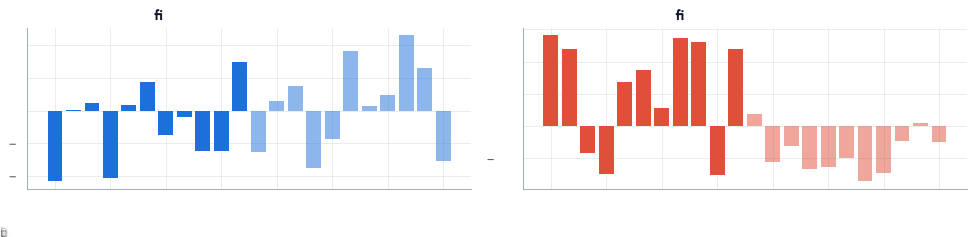

In [7]:
grupos = pd.Series(FEATURES).map(familia).value_counts(sort=False).rename('columnas').to_frame()
display(grupos.T)
R['columnas_por_familia'] = grupos.columnas.to_dict()

# Una foto real del libro: los valores por índice NO salen ordenados
fila = seq.iloc[10_000]
foto = {g: [float(fila[f'i0_{g}{i}']) for i in range(22)] for g in ['p', 'v']}
R['foto_libro'] = foto

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
for a, g, nombre, color in [(ax[0], 'p', 'Precios', AZUL), (ax[1], 'v', 'Volúmenes', CORAL)]:
    colores = [color] * 11 + [color + '80'] * 11
    a.bar(range(22), foto[g], color=colores, width=.8)
    a.set_title(f'{nombre} de i0 en la fila 10.000 (oscuro: bid, claro: ask)')
    a.set_xticks(range(0, 22, 3))
    a.set_xlabel('índice de la columna')
plt.tight_layout()
plt.show()

### Perfil de cada columna

Recorremos la muestra una secuencia a la vez y calculamos, por columna, cuántos valores distintos toma, cuánto cambia de una fila a la siguiente y cuántas veces aparece su valor más repetido. También guardamos 1 de cada 20 filas para hacer histogramas y correlaciones.

In [8]:
def perfil_secuencia(X):
    A = X.to_numpy()
    es_centinela = np.abs(A - CENTINELA) < 1e-3
    limpio = X.where(~es_centinela)
    moda = X.round(4).apply(lambda c: c.value_counts(normalize=True).head(1))
    return pd.DataFrame({
        'media': limpio.mean(), 'desvio': limpio.std(), 'min': limpio.min(), 'max': limpio.max(),
        'cambia': (np.diff(A, axis=0) != 0).mean(0),
        'delta_abs': limpio.diff().abs().mean(),
        'unicos': X.nunique(),
        'centinela': es_centinela.mean(0),
        'moda_valor': moda.apply(lambda c: c.first_valid_index()),
        'moda_frac': moda.max(),
    })


ruta_p, ruta_f = CACHE / 'perfil.parquet', CACHE / 'filas.parquet'
if ruta_p.exists() and ruta_f.exists():
    perfil, filas = pd.read_parquet(ruta_p), pd.read_parquet(ruta_f)
else:
    t = time.time()
    partes_p, partes_f = [], []
    for r in muestra.itertuples():
        df = leer(r.split, r.rg, FEATURES + ['t0', 't1'])
        partes_p.append(perfil_secuencia(df[FEATURES]).assign(split=r.split, inst=r.inst, rg=r.rg).rename_axis('col').reset_index())
        partes_f.append(df.iloc[::20].assign(split=r.split, inst=r.inst, rg=r.rg))
    perfil, filas = pd.concat(partes_p, ignore_index=True), pd.concat(partes_f, ignore_index=True)
    perfil.to_parquet(ruta_p)
    filas.to_parquet(ruta_f)
    print(f'Perfil en {time.time() - t:.0f} s')

perfil['familia'] = perfil.col.map(familia)
perfil['tipo'] = perfil.col.map(tipo)

ritmo = (perfil.groupby('familia', sort=False)
         .agg(columnas=('col', 'nunique'), cambia=('cambia', 'mean'), valores_distintos=('unicos', 'median'),
              moda=('moda_frac', 'mean'), centinela=('centinela', 'mean'), minimo=('min', 'min'), maximo=('max', 'max')))
display(ritmo)
R['ritmo'] = ritmo.reset_index().to_dict('records')

,columnas,cambia,valores_distintos,moda,centinela,minimo,maximo
familia,,,,,,,
i0_p,22,0.266,67.000,0.553,0.000,-2.509,2.419
i0_v,22,0.715,13363.000,0.013,0.000,-2.418,2.439
i0_dp,4,0.378,258.500,0.515,0.000,-2.467,2.661
i0_dv,4,0.186,571.500,0.857,0.000,-3.726,5.199
i1_p,22,0.122,81.500,0.577,0.000,-3.674,5.199
i1_v,22,0.473,10544.000,0.019,0.000,-2.473,2.566
i1_dp,4,0.273,397.000,0.520,0.000,-3.361,5.199
i1_dv,4,0.289,949.500,0.750,0.000,-2.901,5.199
a,8,0.930,17573.500,0.096,0.092,-5.178,5.199


**Tres ritmos muy distintos:**
- Los **volúmenes del libro** cambian en la mayoría de las filas.
- Los **precios** cambian menos. Las columnas de un mismo lado parecen cambiar juntas, porque todas tienen la misma cantidad de valores distintos. Lo comprobamos enseguida.
- Los **volúmenes de trade** repiten un único valor en más de 7 de cada 10 filas.

In [9]:
# ¿Los precios de un mismo lado cambian juntos? Si es así, "alguna cambió" y "todas cambiaron" dan parecido
bid = [f'i0_p{i}' for i in range(11)]
cambios = seq[bid].diff().iloc[1:].ne(0)
alguna, todas = cambios.any(axis=1).mean(), cambios.all(axis=1).mean()
print(f'Lado bid de i0: cambia alguna columna en {alguna:.1%} de las filas, cambian todas en {todas:.1%}')
R['precios_en_bloque'] = {'alguna': float(alguna), 'todas': float(todas)}

Lado bid de i0: cambia alguna columna en 57.4% de las filas, cambian todas en 57.4%


### Valores que no son datos

Dos trampas: el **centinela** −5,1993 y el valor que se repite en los volúmenes de trade.

In [10]:
centinelas = perfil.groupby('col').centinela.mean().loc[lambda s: s > 1e-3].sort_values(ascending=False)
display(centinelas.rename('fracción de filas').to_frame().T)
R['centinelas'] = centinelas.to_dict()

# ¿De dónde sale −5,1993? Es exactamente el cuantil 10⁻⁷ de una normal estándar
tope = NormalDist().inv_cdf(1e-7)
print(f'Φ⁻¹(10⁻⁷) = {tope:.4f}')
R['tope_normal'] = tope

trades = perfil[perfil.familia.isin(['i0_dv', 'i1_dv'])]
display(trades.groupby('col').agg(frac_filas=('moda_frac', 'mean')).T)
display(trades.groupby('inst').moda_valor.agg(['min', 'median', 'max']).rename_axis('valor repetido, por instrumento'))

# ¿Las cuatro columnas dv tienen ese valor en las mismas filas?
DV = [f'i0_dv{i}' for i in range(4)]
en_moda = seq[DV].round(4).eq(seq[DV].round(4).mode().iloc[0])
juntas = en_moda.all(axis=1).sum() / en_moda.any(axis=1).sum()
print(f'De las filas donde alguna dv tiene su valor repetido, en el {juntas:.1%} lo tienen las cuatro')
R['trade_vacio'] = {'dv': float(seq.i0_dv0.round(4).mode()[0]), 'frac_i0': float(perfil[perfil.familia == 'i0_dv'].moda_frac.mean()),
                    'frac_i1': float(perfil[perfil.familia == 'i1_dv'].moda_frac.mean()), 'juntas': float(juntas)}

col,a7,a6,a5
fracción de filas,0.444,0.159,0.135


Φ⁻¹(10⁻⁷) = -5.1993


col,i0_dv0,i0_dv1,i0_dv2,i0_dv3,i1_dv0,i1_dv1,i1_dv2,i1_dv3
frac_filas,0.857,0.857,0.857,0.857,0.750,0.750,0.750,0.750


,min,median,max
"valor repetido, por instrumento",,,
0,0.076,0.076,0.076
1,0.025,0.025,0.025
2,0.038,0.038,0.038
3,0.025,0.025,0.025


De las filas donde alguna dv tiene su valor repetido, en el 100.0% lo tienen las cuatro


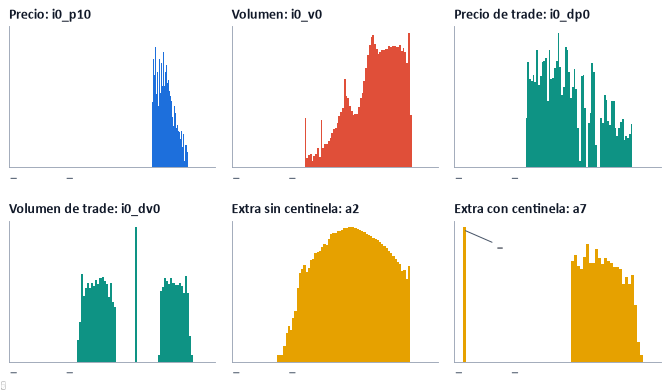

In [11]:
EJEMPLOS = [('i0_p10', 'Precio', AZUL), ('i0_v0', 'Volumen', CORAL), ('i0_dp0', 'Precio de trade', TEAL),
            ('i0_dv0', 'Volumen de trade', TEAL), ('a2', 'Extra sin centinela', AMBAR), ('a7', 'Extra con centinela', AMBAR)]
fig, axes = plt.subplots(2, 3, figsize=(7.6, 4.5))
for a, (col, nombre, color) in zip(axes.flat, EJEMPLOS):
    a.hist(filas[col], bins=60, color=color, log=True)
    a.set_title(f'{nombre}: {col}', fontsize=11)
    a.set_xlim(-5.6, 3.6)
    a.set_yticklabels([])
    a.tick_params(axis='y', which='both', length=0)
    a.grid(False)
axes[1, 2].annotate('−5,1993\n"sin dato"', xy=(-5.2, filas.a7.round(3).eq(-5.199).sum() * .8), xytext=(-3.7, 3e3), fontsize=10.5, color=TINTA,
                    arrowprops=dict(arrowstyle='-', color=GRIS, lw=.8))
plt.tight_layout()
guardar(fig, 'distribuciones')

Los histogramas están en escala logarítmica. Los picos sueltos se ven claros: `a7` tiene casi la mitad de sus filas en −5,1993, y el volumen de trade se concentra en un solo valor, con dos lóbulos a los costados.

**Dos inferencias, no confirmadas por la documentación:**
- −5,1993 es justo Φ⁻¹(10⁻⁷), el tope típico de una normalización a distribución normal, como `QuantileTransformer` de scikit-learn. Todas las filas con el valor mínimo de la columna original terminan ahí. Por eso funciona como "sin dato", aunque el valor crudo podría ser simplemente el más bajo.
- El valor repetido de `dv` aparece a la vez en las cuatro columnas. Parece "sin trade" en esa fila, y los dos lóbulos sugieren volumen con signo (compra o venta).

**Consecuencia práctica:** si se estandariza `a7` sin limpiar, ese valor infla el desvío y la señal real llega aplastada. Lo medimos en la sección 8.

## 4. Secuencias

Acá está la diferencia con una tabla común: **las filas tienen orden**.

- Una secuencia son 20.000 filas consecutivas, con `step_in_seq` de 0 a 19.999.
- Las filas 0 a 98 son **calentamiento**: `need_prediction` es falso.
- Desde la fila 99 hay que predecir en **todas**, aunque solo algunas puntúan (`is_scored`).
- Las secuencias son **independientes**: el estado se reinicia y `seq_ix` no indica orden temporal.

Verifiquemos que eso se cumple de verdad.

,¿se cumple?
20.000 filas y un solo seq_ix,True
step_in_seq es 0…19.999 en orden,True
need_prediction falso solo en 0–98,True
seq_ix no se repite,True
ninguna secuencia está en train y valid a la vez,True


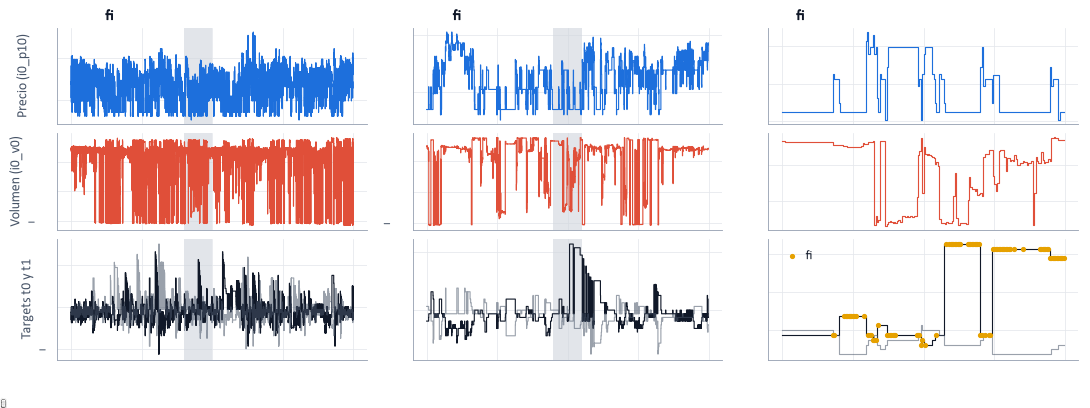

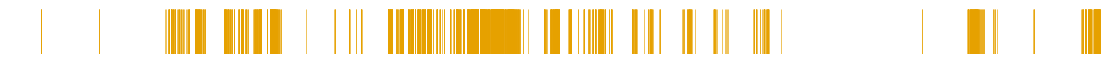

In [12]:
checks = {
    '20.000 filas y un solo seq_ix': len(seq) == 20_000 and seq.seq_ix.nunique() == 1,
    'step_in_seq es 0…19.999 en orden': seq.step_in_seq.eq(np.arange(20_000)).all(),
    'need_prediction falso solo en 0–98': seq.need_prediction.eq(seq.step_in_seq >= 99).all(),
    'seq_ix no se repite': seqs.seq_ix.is_unique,
    'ninguna secuencia está en train y valid a la vez': not set(seqs[seqs.split == 'train'].seq_ix) & set(seqs[seqs.split == 'valid'].seq_ix),
}
display(pd.Series(checks, name='¿se cumple?').to_frame())

# Una secuencia a tres escalas: el mismo dato cuenta historias distintas según el zoom
ej = seqs[(seqs.split == 'valid') & (seqs.inst == 0)].iloc[3]
df = leer('valid', ej.rg)
VENTANAS = [(0, 20_000), (8_000, 10_000), (8_900, 9_100)]
FILAS_G = [('i0_p10', 'Precio (i0_p10)', AZUL), ('i0_v0', 'Volumen (i0_v0)', CORAL)]

fig, axes = plt.subplots(3, 3, figsize=(12.3, 4.7), sharex='col', gridspec_kw={'height_ratios': [1, 1, 1.25]})
for j, (a, b) in enumerate(VENTANAS):
    tramo = df.iloc[a:b]
    x = tramo.step_in_seq
    for i, (col, nombre, color) in enumerate(FILAS_G):
        axes[i, j].plot(x, tramo[col], color=color, lw=.9, drawstyle='steps-post', rasterized=True)
    axes[2, j].plot(x, tramo.t0.clip(-3, 3), color=TINTA, lw=.9, drawstyle='steps-post', rasterized=True)
    axes[2, j].plot(x, tramo.t1.clip(-3, 3), color=GRIS, lw=.9, alpha=.55, drawstyle='steps-post', rasterized=True)
    axes[0, j].set_title(f'{b - a:,} filas'.replace(',', '.'))
    axes[2, j].set_xlabel('step_in_seq')
    if j < 2:  # marca qué parte se amplía en el panel de al lado
        c, d = VENTANAS[j + 1]
        for i in range(3):
            axes[i, j].axvspan(c, d, color='#D0D5DD', alpha=.6, lw=0)
for i, (_, nombre, _) in enumerate(FILAS_G):
    axes[i, 0].set_ylabel(nombre, fontsize=11)
axes[2, 0].set_ylabel('Targets t0 y t1', fontsize=11)
puntuadas = df.iloc[8_900:9_100].loc[lambda d: d.is_scored]
axes[2, 2].scatter(puntuadas.step_in_seq, puntuadas.t0.clip(-3, 3), s=10, color=AMBAR, zorder=5, label='fila puntuada')
axes[2, 2].legend(loc='upper left', fontsize=10, handletextpad=.1)
plt.tight_layout(h_pad=.4)
guardar(fig, 'tres_escalas')
R['tres_escalas'] = {'inst': int(ej.inst), 'seq_ix': int(ej.seq_ix)}

# La máscara de una secuencia típica (con la fracción puntuada más cercana a la media), para el deck
validas = seqs[seqs.split == 'valid']
tipica = validas.iloc[(validas.puntuadas - validas.puntuadas.mean()).abs().argmin()]
m = leer('valid', tipica.rg, ['is_scored']).is_scored.to_numpy()
fig = plt.figure(figsize=(12.13, .5))
ax = fig.add_axes([0, 0, 1, 1])
ax.vlines(np.flatnonzero(m), 0, 1, color=AMBAR, lw=.5)
ax.set(xlim=(0, 20_000), ylim=(0, 1))
ax.axis('off')
fig.savefig(FIG / 'mascara_tira.png', dpi=220, facecolor='white')
plt.show()
R['mascara_tira'] = {'puntuadas': float(m.mean()), 'seq_ix': int(tipica.seq_ix)}

A escala completa parece ruido. Al acercarse aparece la estructura:
- El precio se mueve **a saltos**.
- El volumen se mueve casi todo el tiempo.
- Los targets son **escalones** que se quedan quietos por tramos largos.

## 5. Memoria: ¿hasta dónde importa el pasado?

La herramienta clásica es la **autocorrelación**: ¿cuánto se parece una columna a sí misma `k` filas atrás? En pandas es `serie.autocorr(lag=k)`.

t0, una secuencia: {1: np.float64(0.946), 10: np.float64(0.751), 100: np.float64(0.271), 1000: np.float64(0.031)}


60 s


,1,2,5,10,20,50,100,200,500,1000,2000,5000
familia,,,,,,,,,,,,
i0_p,0.681,0.592,0.475,0.409,0.320,0.188,0.136,0.099,0.043,0.018,0.005,-0.005
i0_v,0.828,0.765,0.637,0.579,0.465,0.340,0.248,0.189,0.103,0.059,0.021,-0.011
i0_dp,0.179,0.241,0.176,0.182,0.143,0.096,0.071,0.062,0.024,0.011,0.003,-0.002
i0_dv,-0.147,0.059,0.047,0.036,0.027,0.017,0.012,0.009,0.005,0.002,0.001,-0.001
i1_p,0.823,0.765,0.661,0.563,0.453,0.311,0.222,0.143,0.067,0.026,0.004,-0.014
i1_v,0.898,0.858,0.772,0.681,0.570,0.414,0.305,0.210,0.109,0.053,0.013,-0.016
i1_dp,0.260,0.328,0.282,0.241,0.197,0.141,0.106,0.074,0.040,0.019,0.008,-0.006
i1_dv,-0.089,0.085,0.072,0.058,0.046,0.031,0.024,0.019,0.011,0.006,0.003,-0.001
a,0.587,0.604,0.501,0.444,0.371,0.270,0.200,0.136,0.073,0.041,0.018,-0.007


,1,2,5,10,20,50,100,200,500,1000,2000,5000
col,,,,,,,,,,,,
a0,0.410,0.387,0.220,0.191,0.143,0.094,0.069,0.048,0.025,0.015,0.007,-0.002
a1,-0.436,0.020,-0.041,0.033,0.035,0.025,0.019,0.013,0.003,0.001,0.001,-0.000
a2,0.988,0.973,0.923,0.836,0.689,0.458,0.323,0.221,0.127,0.074,0.032,-0.012
a3,0.998,0.996,0.988,0.969,0.926,0.794,0.620,0.426,0.230,0.134,0.061,-0.019
a4,0.353,0.285,0.143,0.089,0.057,0.040,0.033,0.022,0.011,0.007,0.003,-0.002
a5,0.892,0.820,0.687,0.561,0.431,0.286,0.208,0.147,0.078,0.044,0.021,-0.005
a6,0.825,0.786,0.705,0.605,0.506,0.346,0.254,0.166,0.090,0.046,0.014,-0.012
a7,0.666,0.568,0.388,0.269,0.182,0.113,0.079,0.050,0.022,0.010,0.004,-0.004


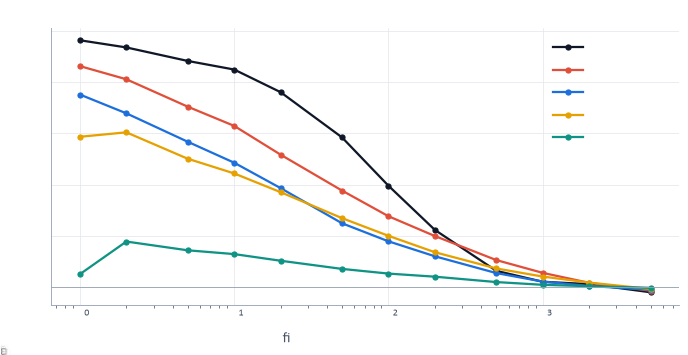

In [13]:
print('t0, una secuencia:', {k: round(df.t0.autocorr(lag=k), 3) for k in [1, 10, 100, 1000]})

# La misma cuenta para todas las columnas de la muestra, restando la media de cada secuencia
LAGS = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000]


def acf_secuencia(df):
    A = df.to_numpy(float)
    limpio = np.where(np.abs(A - CENTINELA) < 1e-3, np.nan, A)
    Z = np.nan_to_num(limpio - np.nanmean(limpio, axis=0))
    v = (Z * Z).sum(0) + 1e-12
    return pd.DataFrame({k: (Z[k:] * Z[:-k]).sum(0) / v for k in LAGS}, index=df.columns)


t = time.time()
partes = [acf_secuencia(leer(r.split, r.rg, FEATURES + ['t0', 't1'])).assign(inst=r.inst, split=r.split) for r in muestra.itertuples()]
acf = pd.concat(partes).rename_axis('col').reset_index()
print(f'{time.time() - t:.0f} s')

acf['familia'] = acf.col.map(familia)
acf['tipo'] = acf.col.map(tipo)
acf_familia = acf.groupby('familia', sort=False)[LAGS].mean()
display(acf_familia)
display(acf[acf.familia == 'a'].groupby('col')[LAGS].mean())

acf_tipo = acf.groupby('tipo')[LAGS].mean().loc[['t0', 't1', 'Volúmenes', 'Precios', 'Extras', 'Trades']]
acf_inst = acf[acf.col == 't0'].groupby('inst')[LAGS].mean()
R['acf'] = {'lags': LAGS, 'tipo': {k: v.tolist() for k, v in acf_tipo.iterrows()}, 'inst': {int(k): v.tolist() for k, v in acf_inst.iterrows()}}

fig, ax = plt.subplots(figsize=(9, 4))
for nombre, color in [('t0', TINTA), ('Volúmenes', CORAL), ('Precios', AZUL), ('Extras', AMBAR), ('Trades', TEAL)]:
    ax.plot(LAGS, acf_tipo.loc[nombre], marker='o', ms=4, color=color, lw=1.8, label=nombre)
ax.set(xscale='log', xlabel='filas hacia atrás (escala log)', ylabel='autocorrelación', title='¿Cuánto se parece cada grupo a sí mismo en el pasado?')
ax.axhline(0, color='#98A2B3', lw=.7)
ax.legend()
plt.show()

**Lectura:** el target casi no cambia de una fila a la siguiente, conserva bastante parecido a 100 filas y **a 1.000 filas ya no queda casi nada**. Dos consecuencias:

1. Tiene sentido un modelo con memoria (RNN), pero no hace falta recordar las 20.000 filas.
2. Dos filas vecinas son casi la misma fila, y eso tiene una consecuencia peligrosa.

### Por qué no se pueden mezclar filas

Si partimos train y validación **por filas al azar**, cada fila de validación queda rodeada de vecinas en train. Veamos qué pasa con el "modelo" más tonto posible: copiar el target de la fila de train inmediatamente anterior.

In [14]:
rng = np.random.default_rng(SEED)
ys, ps = [], []
for r in muestra[muestra.split == 'valid'].itertuples():
    d = leer('valid', r.rg, ['t0', 't1', 'is_scored'])
    en_train = rng.random(len(d)) < .8
    copia = d[['t0', 't1']].where(np.c_[en_train, en_train]).ffill()  # target de la última fila de train
    m = d.is_scored.to_numpy() & ~en_train & copia.t0.notna().to_numpy()
    ys.append(d.loc[m, ['t0', 't1']].to_numpy())
    ps.append(copia.loc[m].to_numpy())
ys, ps = np.vstack(ys), np.vstack(ps)
fuga = (wp_global(ys[:, 0], ps[:, 0]) + wp_global(ys[:, 1], ps[:, 1])) / 2
print(f'WP de copiar a la vecina con un split por filas: {fuga:.3f}')
R['fuga_wp'] = float(fuga)

WP de copiar a la vecina con un split por filas: 0.985


Da un puntaje casi perfecto **sin aprender nada**, muy por encima de un ensamble real del proyecto (0,686). Es filtración pura: en el test no están los targets de las filas vecinas.

**Regla:** se valida siempre por **secuencias completas**.

### Cada secuencia tiene su propia escala

Dentro de una misma columna, algunas secuencias se mueven mucho y otras casi nada. Una normalización global no lo corrige.

,veces,frac_entre
familia,,
a,2.129,0.156
i0_dp,2.149,0.081
i0_dv,3.610,0.014
i0_p,7.005,0.186
i0_v,5.267,0.312
i1_dp,2.590,0.093
i1_dv,3.606,0.029
i1_p,8.954,0.127
i1_v,6.395,0.249


Mediana: el desvío de una columna varía 5.7 veces entre secuencias (p95/p5). Peor: i1_p9 con 20.4x


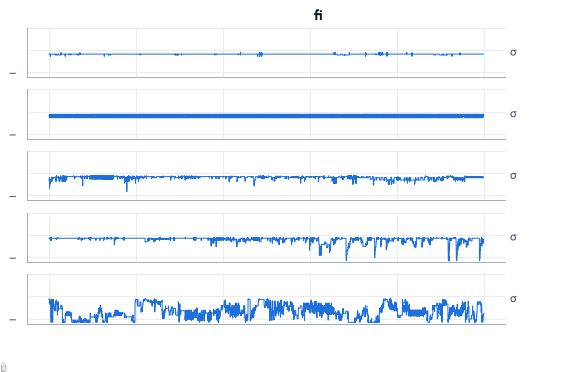

|t0| medio por tramo de 1.000 filas: de 0.709 a 0.723: la posición no cambia la escala


In [15]:
por_col = perfil.groupby('col')
escala = por_col.desvio.quantile([.05, .95]).unstack()
escala['veces'] = escala[.95] / escala[.05]
entre = por_col.media.var()
dentro = por_col.desvio.apply(lambda s: (s ** 2).mean())
escala['frac_entre'] = entre / (entre + dentro)
escala['familia'] = escala.index.map(familia)
escala['tipo'] = escala.index.map(tipo)
display(escala.groupby('familia', sort=False)[['veces', 'frac_entre']].mean())
R['escala'] = {'mediana_veces': float(escala.veces.median()), 'cols_mas_2x': int((escala.veces > 2).sum()), 'cols_mas_3x': int((escala.veces > 3).sum()),
               'peor_col': escala.veces.idxmax(), 'peor_veces': float(escala.veces.max()),
               'veces_tipo': escala.groupby('tipo').veces.median().to_dict(), 'entre_tipo': escala.groupby('tipo').frac_entre.mean().to_dict(),
               'entre_max_col': escala.frac_entre.idxmax(), 'entre_max': float(escala.frac_entre.max())}
print(f"Mediana: el desvío de una columna varía {R['escala']['mediana_veces']:.1f} veces entre secuencias (p95/p5). Peor: {R['escala']['peor_col']} con {R['escala']['peor_veces']:.1f}x")

# La misma columna en cinco secuencias con distinto desvío: mismo eje, comportamientos muy distintos
COL = 'i0_p9'
d_col = perfil[perfil.col == COL].sort_values('desvio')
elegidas = d_col.iloc[np.linspace(0, len(d_col) - 1, 5).astype(int)]
fig, axes = plt.subplots(5, 1, figsize=(6.4, 4.3), sharex=True, sharey=True)
for a, r in zip(axes, elegidas.itertuples()):
    v = leer(r.split, r.rg, [COL])[COL].iloc[:5000]
    a.plot(v.to_numpy(), color=AZUL, lw=.8, drawstyle='steps-post', rasterized=True)
    a.text(1.01, .5, f'σ = {r.desvio:.2f}'.replace('.', ','), transform=a.transAxes, va='center', fontsize=10.5, color=GRIS)
    a.set_yticks([-2, 0, 2])
axes[0].set_title(f'{COL} en cinco secuencias (primeras 5.000 filas)')
axes[-1].set_xlabel('step_in_seq')
plt.tight_layout(h_pad=.15)
guardar(fig, 'escala_secuencias')

# ¿Hay deriva con la posición? |t0| medio por tramo, en todas las secuencias
pos = seqs.filter(like='pos_').mean().to_numpy()
print(f'|t0| medio por tramo de 1.000 filas: de {pos.min():.3f} a {pos.max():.3f}: la posición no cambia la escala')
R['deriva_pos'] = {'min': float(pos.min()), 'max': float(pos.max())}

## 6. Targets

`t0` y `t1` son dos indicadores del movimiento futuro de `i0`. Su definición exacta no se publica, pero los datos dicen bastante:

,"corr(t0, t1) media por secuencia",filas con t0 = 0,filas con t1 = 0,filas con |t0| > 2,filas donde cambia t0,filas con t0 y t1 positivos a la vez,máximo |t|
valor,-0.794,0.219,0.218,0.030,0.080,0.000,179.918


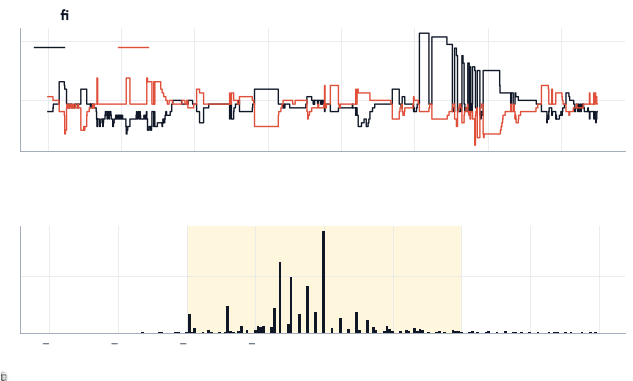

In [16]:
resumen_t = {
    'corr(t0, t1) media por secuencia': seqs.corr_t0_t1.mean(),
    'filas con t0 = 0': seqs.t0_cero.mean(),
    'filas con t1 = 0': seqs.t1_cero.mean(),
    'filas con |t0| > 2': seqs.t0_fuera.mean(),
    'filas donde cambia t0': seqs.t0_cambia.mean(),
    'filas con t0 y t1 positivos a la vez': seqs.ambos_positivos.sum() / (len(seqs) * 20_000),
    'máximo |t|': seqs.t_max.max(),
}
display(pd.Series(resumen_t, name='valor').to_frame().T)
R['targets'] = {k: float(v) for k, v in dict(corr=seqs.corr_t0_t1.mean(), cero_t0=seqs.t0_cero.mean(), cero_t1=seqs.t1_cero.mean(),
                                             fuera=(seqs.t0_fuera.mean() + seqs.t1_fuera.mean()) / 2, cambia_t0=seqs.t0_cambia.mean(), cambia_t1=seqs.t1_cambia.mean(),
                                             ambos=seqs.ambos_positivos.sum(), maximo=seqs.t_max.max()).items()}

fig, ax = plt.subplots(2, 1, figsize=(7.2, 4.4), gridspec_kw={'height_ratios': [1.15, 1]})
tramo = df.iloc[8_000:9_500]
ax[0].plot(tramo.step_in_seq, tramo.t0.clip(-3, 3), color=TINTA, lw=1.1, drawstyle='steps-post', label='t0')
ax[0].plot(tramo.step_in_seq, tramo.t1.clip(-3, 3), color=CORAL, lw=1.1, drawstyle='steps-post', label='t1')
ax[0].set_title('1.500 filas reales: los targets se mueven a saltos')
ax[0].legend(loc='upper left', ncols=2)
ax[0].set_xlabel('step_in_seq')
b = np.arange(-4.02, 4.02, .04)
ax[1].hist(filas.t0, bins=b, color=TINTA)
ax[1].axvspan(-2, 2, color='#FEF0C7', alpha=.6, lw=0, zorder=0)
ax[1].set_title('Distribución de t0 (muestra): picos en valores discretos')
ax[1].set_yticklabels([])
ax[1].set_xlabel('t0 (franja: lo que deja la métrica tras recortar a ±2)')
plt.tight_layout()
guardar(fig, 'escalones')

**Tres rasgos:**
1. **Son discretos.** No es una curva, son saltos múltiplos de un escalón.
2. **Están muy quietos.** Cambian en menos de 1 de cada 10 filas.
3. **Son opuestos y nunca ambos positivos.** En las 249,6 millones de filas no aparece ni una con `t0 > 0` y `t1 > 0`.

Para entender el tercero, conviene pasar los targets a **ticks**, dividiendo por el escalón. Eso nos lleva a los instrumentos.

## 7. Los datos son 4 instrumentos

El escalón mínimo del target no varía de forma continua entre secuencias: toma **cuatro valores exactos**. Cada secuencia pertenece a uno de 4 mercados distintos. No hay ninguna columna que lo diga, pero se puede deducir.

In [17]:
display(seqs.paso_minimo.round(4).value_counts().head(6).rename('secuencias').to_frame().T)

print('Sospechosa: 0,9371 = 2 × 0,46853. Esa secuencia no tiene pasos de un solo escalón, pero sus valores son múltiplos de 0,46853.')
print('Máximo error de múltiplo entero, en todas las secuencias:', f'{seqs.error_inst.max():.1e}')

mezcla = seqs.groupby(['inst', 'split']).size().unstack()
mezcla_pct = mezcla / mezcla.sum()
unicos = perfil[perfil.col == 'i0_p10'].groupby('inst').unicos.median()
instr = pd.DataFrame({
    'cuanto': CUANTOS, 'seq_train': mezcla.train, 'seq_valid': mezcla.valid, 'pct_train': mezcla_pct.train, 'pct_valid': mezcla_pct.valid,
    'precios_distintos': unicos, 't_desvio': seqs.groupby('inst')[['t0_std', 't1_std']].mean().mean(axis=1),
    'corr_t0_t1': seqs.groupby('inst').corr_t0_t1.mean(), 'cero': seqs.groupby('inst')[['t0_cero', 't1_cero']].mean().mean(axis=1),
    'cambia': seqs.groupby('inst')[['t0_cambia', 't1_cambia']].mean().mean(axis=1), 'puntuadas': seqs.groupby('inst').puntuadas.mean(),
})
display(instr)
R['instrumentos'] = instr.reset_index().to_dict('records')

paso_minimo,0.657,0.468,0.125,0.241,0.937
secuencias,5254,3918,1703,1604,1


Sospechosa: 0,9371 = 2 × 0,46853. Esa secuencia no tiene pasos de un solo escalón, pero sus valores son múltiplos de 0,46853.
Máximo error de múltiplo entero, en todas las secuencias: 5.7e-03


,cuanto,seq_train,seq_valid,pct_train,pct_valid,precios_distintos,t_desvio,corr_t0_t1,cero,cambia,puntuadas
inst,,,,,,,,,,,
0,0.125,1305,398,0.123,0.212,698.000,0.921,-0.564,0.054,0.149,0.124
1,0.241,1257,347,0.119,0.185,153.500,0.941,-0.662,0.122,0.115,0.077
2,0.469,3488,431,0.329,0.230,20.000,0.931,-0.834,0.214,0.046,0.033
3,0.657,4557,697,0.430,0.372,10.000,0.918,-0.878,0.304,0.074,0.123


**El instrumento 3 es de "tick grande":** el precio toma unos pocos valores en 20.000 filas. El instrumento 0 tiene cientos.

El desvío del target es casi igual en los cuatro (~0,92), así que un tick del 3 vale cinco veces más que uno del 0. Por eso el mismo número significa cosas distintas según el mercado.

### Estados en ticks

Cada celda muestra con qué frecuencia aparece cada par (`t0`, `t1`) en ticks. Se usan todas las secuencias de valid.

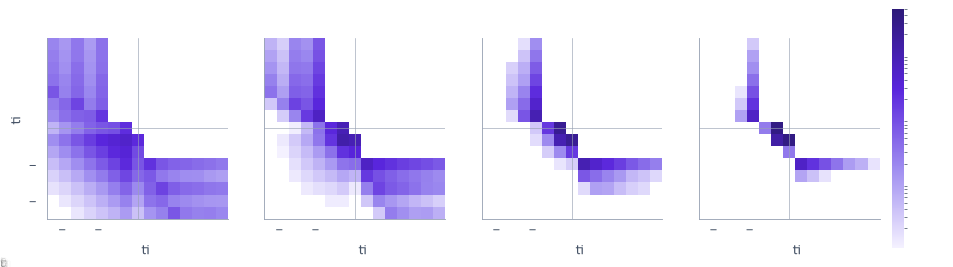

Instrumento 0: [(-1, -1, 0.048), (-2, -1, 0.036), (-1, -2, 0.035), (-3, -1, 0.028), (-2, -2, 0.026)]
Instrumento 1: [(-1, -1, 0.122), (0, -1, 0.091), (-1, 0, 0.088), (-3, 1, 0.059), (1, -3, 0.057)]
Instrumento 2: [(-1, 0, 0.226), (0, -1, 0.224), (1, -3, 0.093), (-3, 1, 0.092), (-1, -1, 0.092)]
Instrumento 3: [(0, -1, 0.341), (-1, 0, 0.339), (-1, -1, 0.134), (-3, 1, 0.055), (1, -3, 0.053)]


In [18]:
TOPE = 7
fig, axes = plt.subplots(1, 4, figsize=(12.3, 3.45), sharey=True)
estados = {}
for k, a in enumerate(axes):
    filas_k = seqs[(seqs.split == 'valid') & (seqs.inst == k)]
    t = np.vstack([np.c_[d.t0.to_numpy(), d.t1.to_numpy()] for d in (leer('valid', g, ['t0', 't1']) for g in filas_k.rg)])
    ticks = pd.DataFrame(np.round(t / CUANTOS[k]).astype(int), columns=['t0', 't1'])
    frec = ticks.value_counts(normalize=True)
    estados[k] = [dict(t0=int(i), t1=int(j), frac=float(v)) for (i, j), v in frec.head(6).items()]
    H = frec.unstack(fill_value=0).reindex(index=range(-TOPE, TOPE + 1), columns=range(-TOPE, TOPE + 1), fill_value=0).to_numpy().T
    im = a.imshow(H, origin='lower', extent=(-TOPE - .5, TOPE + .5, -TOPE - .5, TOPE + .5), cmap=SECUENCIAL, norm=LogNorm(1e-4, .5))
    a.set_facecolor('#FFFFFF')
    H_ = np.ma.masked_less(H, 1e-4)
    a.images[0].set_data(H_)
    a.axhline(0, color='#98A2B3', lw=.5)
    a.axvline(0, color='#98A2B3', lw=.5)
    a.grid(False)
    a.set_xticks([-6, -3, 0, 3, 6])
    a.set_yticks([-6, -3, 0, 3, 6])
    a.set_title(f'Instrumento {k}')
    a.set_xlabel('t0 en ticks')
axes[0].set_ylabel('t1 en ticks')
cb = fig.colorbar(im, ax=axes, fraction=.015, pad=.015, ticks=[1e-4, 1e-3, 1e-2, 1e-1])
cb.ax.set_yticklabels(['0,01 %', '0,1 %', '1 %', '10 %'], fontsize=10)
cb.outline.set_visible(False)
guardar(fig, 'estados_ticks')
R['estados'] = estados
for k in estados:
    print(f'Instrumento {k}:', [(e['t0'], e['t1'], round(e['frac'], 3)) for e in estados[k][:5]])

El cuadrante de arriba a la derecha (`t0 > 0` y `t1 > 0`) está **vacío en los cuatro**. En el instrumento 3 casi todo se reduce a dos estados de "no se mueve", (0, −1) y (−1, 0), más unos pocos saltos.

### Cuatro personalidades

La misma columna y el mismo target en una secuencia real de cada instrumento.

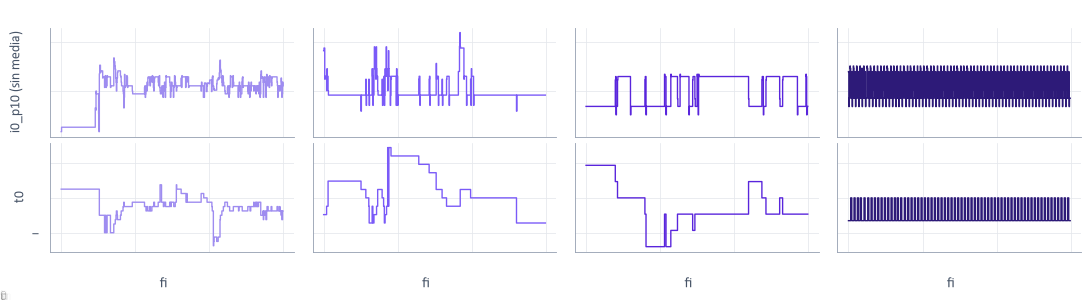

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(12.3, 3.5), sharex=True, sharey='row', gridspec_kw={'height_ratios': [1, 1]})
for k in range(4):
    # La secuencia típica de cada instrumento: la de ritmo de cambio más cercano a la mediana
    candidatas = seqs[(seqs.split == 'valid') & (seqs.inst == k)]
    r = candidatas.iloc[(candidatas.t0_cambia - candidatas.t0_cambia.median()).abs().argmin()]
    d = leer('valid', r.rg, ['i0_p10', 't0']).iloc[6_000:6_600]
    axes[0, k].plot(np.arange(600), d.i0_p10.to_numpy() - d.i0_p10.mean(), color=INST[k], lw=1.1, drawstyle='steps-post')
    axes[1, k].plot(np.arange(600), d.t0.clip(-3, 3).to_numpy(), color=INST[k], lw=1.1, drawstyle='steps-post')
    axes[0, k].set_title(f'Instrumento {k}')
    axes[1, k].set_xlabel('filas')
axes[0, 0].set_ylabel('i0_p10 (sin media)', fontsize=11)
axes[1, 0].set_ylabel('t0', fontsize=11)
plt.tight_layout(h_pad=.4)
guardar(fig, 'cuatro_instrumentos')

### ¿Se puede saber el instrumento sin mirar el target?

Sí. Algunas columnas repiten valores exactos que casi no se comparten entre instrumentos. Armamos una tabla de valores de `a7` **solo con train** y la probamos en valid, mirando únicamente el calentamiento (las primeras 99 filas). Sirve porque en el test no hay targets.

In [20]:
tabla = {k: set() for k in range(4)}
for r in muestra[muestra.split == 'train'].itertuples():
    v = leer('train', r.rg, ['a7']).a7.to_numpy()
    tabla[r.inst] |= set(v[np.abs(v - CENTINELA) > 1e-3].tolist())

aciertos = sin_decidir = 0
for r in muestra[muestra.split == 'valid'].itertuples():
    v = set(leer('valid', r.rg, ['a7']).a7.to_numpy()[:99].tolist())
    votos = [len(v & tabla[k]) for k in range(4)]
    if max(votos) == 0:
        sin_decidir += 1
    aciertos += int(max(votos) > 0 and int(np.argmax(votos)) == r.inst)
n = (muestra.split == 'valid').sum()
print(f'Aciertos en valid: {aciertos}/{n} · sin decidir: {sin_decidir}')
R['deteccion_a7'] = {'aciertos': int(aciertos), 'n': int(n), 'sin_decidir': int(sin_decidir)}

Aciertos en valid: 100/100 · sin decidir: 0


## 8. Correlación

Cuatro preguntas:
1. ¿Qué tan redundantes son las 112 columnas entre sí?
2. ¿Qué tanto predice el target cada columna sola?
3. ¿La señal está en el valor actual o en cómo viene cambiando?
4. ¿Sirve de verdad mirar el pasado?

### 8.1. Entre variables

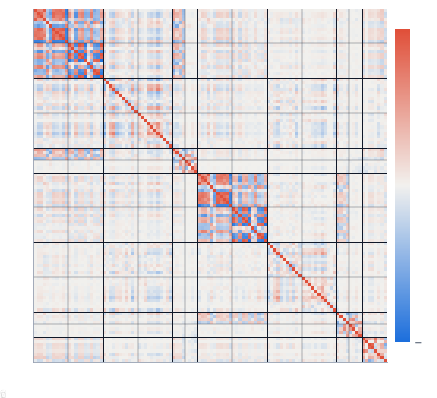

,i0_p,i0_v,i0_dp,i0_dv,i1_p,i1_v,i1_dp,i1_dv,a
i0_p,0.513,0.100,0.336,0.019,0.093,0.036,0.040,0.015,0.114
i0_v,0.100,0.165,0.072,0.022,0.057,0.078,0.064,0.027,0.038
i0_dp,0.336,0.072,0.239,0.263,0.052,0.025,0.030,0.024,0.106
i0_dv,0.019,0.022,0.263,0.317,0.006,0.016,0.028,0.031,0.041
i1_p,0.093,0.057,0.052,0.006,0.446,0.038,0.220,0.015,0.055
i1_v,0.036,0.078,0.025,0.016,0.038,0.117,0.044,0.021,0.038
i1_dp,0.040,0.064,0.030,0.028,0.220,0.044,0.162,0.293,0.063
i1_dv,0.015,0.027,0.024,0.031,0.015,0.021,0.293,0.310,0.040
a,0.114,0.038,0.106,0.041,0.055,0.038,0.063,0.040,0.300


Componentes para explicar % de la varianza: {50: 11, 80: 39, 90: 55, 95: 67}
Fracción de varianza en la primera componente de cada bloque: {'i0_p': 0.55, 'i0_v': 0.234, 'i1_p': 0.477, 'i1_v': 0.164}


In [21]:
X = filas[FEATURES].where(lambda d: (d - CENTINELA).abs() > 1e-3)  # sin centinelas
corr = X.corr()

CORTES = [0, 11, 22, 33, 44, 48, 52, 63, 74, 85, 96, 100, 104, 112]
GRUPOS_EJE = [(11, 'i0 p'), (33, 'i0 v'), (46, 'dp'), (50, 'dv'), (63, 'i1 p'), (85, 'i1 v'), (98, 'dp'), (102, 'dv'), (108, 'a')]
fig, ax = plt.subplots(figsize=(5.6, 5.1))
im = ax.imshow(corr, cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -1, 1), interpolation='nearest')
for c in CORTES[1:-1]:
    grueso = c in (22, 44, 52, 74, 96, 104)
    ax.axhline(c - .5, color=TINTA, lw=.8 if grueso else .25)
    ax.axvline(c - .5, color=TINTA, lw=.8 if grueso else .25)
ax.set_xticks([p for p, _ in GRUPOS_EJE], [n for _, n in GRUPOS_EJE], fontsize=9.5, rotation=45, ha='right', rotation_mode='anchor')
ax.set_yticks([p for p, _ in GRUPOS_EJE], [n for _, n in GRUPOS_EJE], fontsize=9.5)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=.04, pad=.02, ticks=[-1, 0, 1])
cb.outline.set_visible(False)
guardar(fig, 'corr_features')

# Promedio de |corr| entre grupos (sin la diagonal)
valores = corr.abs().to_numpy(copy=True)
np.fill_diagonal(valores, np.nan)
fam = pd.Series(FEATURES).map(familia).to_numpy()
abs_corr = pd.DataFrame(valores, index=fam, columns=fam)
bloques = abs_corr.T.groupby(level=0, sort=False).mean().T.groupby(level=0, sort=False).mean()
display(bloques)

# Componentes principales: cuántas dimensiones hacen falta
autov = np.linalg.eigvalsh(corr.fillna(0).to_numpy())[::-1]
acum = np.cumsum(autov) / autov.sum()
pca = {p: int(np.searchsorted(acum, p / 100) + 1) for p in [50, 80, 90, 95]}
print('Componentes para explicar % de la varianza:', pca)

pc1 = {}
for f in ['i0_p', 'i0_v', 'i1_p', 'i1_v']:
    cols = [c for c in FEATURES if familia(c) == f]
    a = np.linalg.eigvalsh(corr.loc[cols, cols].to_numpy())
    pc1[f] = float(a[-1] / a.sum())
print('Fracción de varianza en la primera componente de cada bloque:', {k: round(v, 3) for k, v in pc1.items()})

mitad = pd.Series(corr.loc[[c for c in FEATURES if familia(c) == 'i0_p'], [c for c in FEATURES if familia(c) == 'i1_p']].abs().to_numpy().ravel())
R['corr_features'] = {'pca': pca, 'pc1': pc1, 'bloques': {f: {g: float(bloques.loc[f, g]) for g in bloques.columns} for f in bloques.index},
                      'i0p_i1p_max': float(mitad.max()), 'n_pares_mayor_08': int((np.nan_to_num(valores) > .8).sum() // 2), 'n_pares': 112 * 111 // 2}

Se ven bloques claros, pero no todos iguales. **Los precios son muy redundantes:** una sola componente concentra más de la mitad de la varianza de los 22 precios de `i0`. Los volúmenes se parecen mucho menos entre sí, y en conjunto hacen falta 55 componentes para llegar al 90 %. No se puede tirar la mitad de las columnas sin perder información.

**Cuidado con la lectura:** esta correlación es *pooled* entre secuencias, así que mezcla lo que varía dentro de la secuencia con lo que varía entre secuencias.

### 8.2. Con el target, y a distintos retrasos

Medimos `corr(x en t+k, y en t)` por instrumento, para cada columna:
- Con **k negativo**, la variable es del **pasado**: es lo único que puede usar el modelo.
- Con **k positivo**, la variable es del **futuro**: el modelo no la tiene, pero nos dice hacia dónde mira el target.

83 s


,inst,col,target,abs
20,0,i0_p10,t0,0.353
257,1,i0_p16,t1,0.229
469,2,i0_p10,t1,0.135
758,3,i0_v21,t0,0.164


inst 0 t0: i0_p10 -0.35, i0_p3 +0.35, i0_p0 +0.35, i0_p9 +0.35, i0_p8 +0.32, i0_p6 +0.31
inst 0 t1: i0_p20 -0.34, i0_p19 -0.34, i0_p21 +0.34, i0_p14 +0.34, i0_p16 -0.34, i0_p11 +0.33
inst 1 t0: i0_p10 -0.20, i0_p0 +0.20, i0_p3 +0.20, i0_p9 +0.19, i0_p1 +0.18, i0_p8 +0.18
inst 1 t1: i0_p16 -0.23, i0_p21 +0.22, i0_p19 -0.22, i0_p14 +0.21, i0_p20 -0.21, i0_p11 +0.21
inst 2 t0: i0_p0 +0.13, i0_p7 +0.13, i0_p3 +0.13, i0_p10 -0.13, i0_p18 +0.13, i0_p16 -0.13
inst 2 t1: i0_p10 -0.13, i0_p15 +0.13, i0_p1 +0.13, i0_p2 +0.13, i0_p6 +0.13, i0_p21 +0.13
inst 3 t0: i0_v21 +0.16, i0_p13 -0.13, i0_p20 -0.13, i0_p18 +0.13, i0_p16 -0.13, i0_p19 -0.13
inst 3 t1: i0_p2 +0.15, i0_p1 +0.15, i0_p6 +0.14, i0_p14 +0.14, i0_p9 +0.14, i0_p10 -0.14


,-1000,-100,-10,-1,0,1,10,100,1000
i0_p,0.018,0.040,0.078,0.110,0.131,0.112,0.086,0.042,0.017
i0_dp,0.014,0.031,0.057,0.080,0.088,0.094,0.069,0.041,0.016
i1_p,0.009,0.014,0.020,0.022,0.022,0.023,0.026,0.020,0.011
i0_v,0.011,0.014,0.024,0.032,0.035,0.033,0.026,0.018,0.016
a,0.019,0.026,0.032,0.037,0.038,0.038,0.033,0.023,0.016


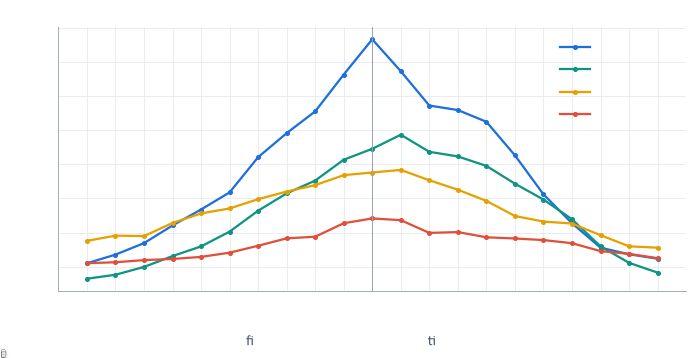

In [22]:
CCF_LAGS = [-2000, -1000, -500, -200, -100, -50, -20, -10, -5, -1, 0, 1, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]
n = len(FEATURES)
acum = {(i, k): dict(n=0, sx=np.zeros(n), sxx=np.zeros(n), sy=np.zeros(2), syy=np.zeros(2), sxy=np.zeros((n, 2))) for i in range(4) for k in CCF_LAGS}

t0_reloj = time.time()
for r in muestra.itertuples():
    d = leer(r.split, r.rg, FEATURES + ['t0', 't1'])
    A = d[FEATURES].to_numpy(float, copy=True)
    A[np.abs(A - CENTINELA) < 1e-3] = 0
    Y = d[['t0', 't1']].clip(-2, 2).to_numpy(float)
    for k in CCF_LAGS:
        x_, y_ = (A[k:], Y[:-k]) if k > 0 else (A[:k], Y[-k:]) if k < 0 else (A, Y)
        a = acum[(r.inst, k)]
        a['n'] += len(x_); a['sx'] += x_.sum(0); a['sxx'] += (x_ * x_).sum(0); a['sy'] += y_.sum(0); a['syy'] += (y_ * y_).sum(0); a['sxy'] += x_.T @ y_
print(f'{time.time() - t0_reloj:.0f} s')


def corr_acumulada(a):
    N = a['n']
    mx, my = a['sx'] / N, a['sy'] / N
    vx, vy = a['sxx'] / N - mx ** 2, a['syy'] / N - my ** 2
    return (a['sxy'] / N - np.outer(mx, my)) / np.sqrt(np.outer(vx, vy) + 1e-18)


C = {clave: corr_acumulada(a) for clave, a in acum.items()}
c0 = pd.concat({i: pd.DataFrame(C[(i, 0)], index=FEATURES, columns=['t0', 't1']) for i in range(4)}, names=['inst', 'col'])
mejor = c0.abs().stack().rename('abs').reset_index().rename(columns={'level_2': 'target'}).sort_values('abs', ascending=False).groupby('inst').head(1).sort_values('inst')
display(mejor)
for i in range(4):
    for tgt in ['t0', 't1']:
        top = c0.loc[i][tgt].sort_values(key=np.abs, ascending=False).head(6)
        print(f'inst {i} {tgt}:', ', '.join(f'{c} {v:+.2f}' for c, v in top.items()))

media_inst = c0.groupby('col').mean().loc[FEATURES]
top_t0, top_t1 = [media_inst[t].sort_values(key=np.abs, ascending=False).head(10) for t in ['t0', 't1']]
R['corr_target'] = {
    'mejor_por_inst': mejor.to_dict('records'),
    'top_t0': [dict(col=c, r=float(v)) for c, v in top_t0.items()], 'top_t1': [dict(col=c, r=float(v)) for c, v in top_t1.items()],
    'mediana_abs': float(c0.abs().median().mean()), 'p90_abs': float(c0.abs().quantile(.9).mean()),
    'lado': {int(i): {t: {'bid': float(c0.loc[i][t].iloc[:11].abs().mean()), 'ask': float(c0.loc[i][t].iloc[11:22].abs().mean())} for t in ['t0', 't1']} for i in range(4)},
}

# Señal media por tipo de variable según el retraso: promedio de |corr| entre instrumentos y targets
serie = {k: np.mean([np.abs(C[(i, k)]).mean(axis=1) for i in range(4)], axis=0) for k in CCF_LAGS}
ccf = pd.DataFrame(serie, index=FEATURES).T
ccf_tipo = ccf.T.groupby(tipo).mean().T
ccf_fam = ccf.T.groupby(familia, sort=False).mean().T
ccf_max = pd.DataFrame({k: np.mean([np.abs(C[(i, k)]).max(axis=0) for i in range(4)], axis=0) for k in CCF_LAGS}, index=['t0', 't1']).T
display(ccf_fam.T.loc[['i0_p', 'i0_dp', 'i1_p', 'i0_v', 'a'], [-1000, -100, -10, -1, 0, 1, 10, 100, 1000]])
R['ccf'] = {'lags': CCF_LAGS, 'tipo': {c: ccf_tipo[c].tolist() for c in ccf_tipo}, 'familia': {c: ccf_fam[c].tolist() for c in ccf_fam}, 'max_t0': ccf_max.t0.tolist(), 'max_t1': ccf_max.t1.tolist()}

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(CCF_LAGS))
for nombre, color in [('Precios', AZUL), ('Trades', TEAL), ('Extras', AMBAR), ('Volúmenes', CORAL)]:
    ax.plot(x, ccf_tipo[nombre], color=color, lw=1.8, marker='o', ms=3, label=nombre)
ax.axvline(CCF_LAGS.index(0), color='#98A2B3', lw=.8)
ax.set_xticks(x, CCF_LAGS, rotation=45)
ax.set(xlabel='k: filas respecto del target (negativo = pasado)', ylabel='|corr| media', title='¿Dónde está la señal?')
ax.legend()
plt.show()

**Lectura:**
- Ninguna columna sola llega lejos: el máximo por instrumento es 0,35 y la columna típica correlaciona alrededor de 0,03.
- La señal más fuerte está en los **precios de `i0`**.
- En los instrumentos 0 y 1, `t0` se relaciona con los precios bid y `t1` con los ask. En el 2 y el 3 esa separación desaparece: cada instrumento se comporta distinto.
- La señal cae hacia ambos lados y **a 1.000 filas ya casi no queda nada**, igual que la autocorrelación.

### 8.3. El efecto del centinela

La misma columna, antes y después de sacar el −5,1993, medida en todas las filas puntuadas de valid.

In [23]:
acumulado = []
for r in seqs[seqs.split == 'valid'].itertuples():
    d = leer('valid', r.rg, ['a7', 't1', 'is_scored'])
    acumulado.append(d[d.is_scored][['a7', 't1']])
a7 = pd.concat(acumulado, ignore_index=True)
crudo = a7.a7.corr(a7.t1.clip(-2, 2))
limpio = a7.a7.where((a7.a7 - CENTINELA).abs() > 1e-3).corr(a7.t1.clip(-2, 2))
print(f'corr(a7, t1) cruda: {crudo:.3f} · sin centinela: {limpio:.3f} · filas con centinela: {(a7.a7 - CENTINELA).abs().lt(1e-3).mean():.1%}')
R['a7'] = {'crudo': float(crudo), 'limpio': float(limpio), 'frac': float((a7.a7 - CENTINELA).abs().lt(1e-3).mean())}
del a7, acumulado

corr(a7, t1) cruda: 0.015 · sin centinela: 0.116 · filas con centinela: 42.1%


### 8.4. ¿Valor actual, cambio o desvío?

Es la pregunta típica de una serie temporal: ¿importa el nivel, el cambio contra la fila anterior o la distancia a un promedio reciente? Pandas lo hace en tres líneas con `.diff()` y `.ewm()`.

In [24]:
registros = []
for r in muestra[muestra.split == 'valid'].itertuples():
    d = leer('valid', r.rg, FEATURES + ['t0'])
    x = d[FEATURES].where(lambda v: (v - CENTINELA).abs() > 1e-3)
    y = d.t0.clip(-2, 2)
    transformaciones = {'nivel': x, 'cambio (diff)': x.diff(), 'desvío de EWM(100)': x - x.ewm(span=100).mean()}
    registros.append(pd.DataFrame({n: v.corrwith(y).abs() for n, v in transformaciones.items()}).assign(familia=[familia(c) for c in FEATURES]))
transf = pd.concat(registros).groupby('familia', sort=False).mean()
display(transf)
R['transformaciones'] = transf.reset_index().to_dict('records')

,nivel,cambio (diff),desvío de EWM(100)
familia,,,
i0_p,0.148,0.049,0.118
i0_v,0.091,0.021,0.066
i0_dp,0.092,0.027,0.072
i0_dv,0.030,0.003,0.020
i1_p,0.053,0.003,0.028
i1_v,0.051,0.003,0.025
i1_dp,0.046,0.002,0.022
i1_dv,0.031,0.001,0.016
a,0.068,0.021,0.035


### 8.5. ¿Sirve de verdad mirar el pasado?

La prueba más limpia que entra en un notebook es comparar **el mismo modelo lineal, ajustado solo con train y medido en TODO valid** con la métrica oficial:

- **Sin memoria:** las 112 columnas de la fila actual.
- **Con memoria:** las mismas, más sus promedios móviles exponenciales de 10, 100 y 1.000 filas. Son causales: solo miran el pasado.

Es la versión más simple posible de lo que hace una red recurrente. Tarda unos 10 minutos y queda en caché.

In [25]:
VENTANAS_EWM = [10, 100, 1000]
N_TRAIN_LINEAL = 240


def entradas(tabla, con_memoria):
    A = np.column_stack([tabla[c].to_numpy() for c in FEATURES]).astype(np.float32)
    A[np.abs(A - CENTINELA) < 1e-3] = 0
    if not con_memoria:
        return A
    d = pd.DataFrame(A)
    return np.hstack([A] + [d.ewm(span=w).mean().to_numpy(dtype=np.float32) for w in VENTANAS_EWM])


def lineal(con_memoria):
    XtX, Xty = None, None
    for r in seqs[seqs.split == 'train'].sample(N_TRAIN_LINEAL, random_state=SEED).itertuples():
        tb = ARCHIVOS['train'].read_row_group(int(r.rg), columns=FEATURES + ['t0', 't1'])
        M = entradas(tb, con_memoria)[99::5]
        M = np.c_[np.ones(len(M)), M].astype(float)
        y = np.clip(np.c_[tb['t0'].to_numpy(), tb['t1'].to_numpy()], -2, 2)[99::5].astype(float)
        if XtX is None:
            XtX = [np.zeros((M.shape[1],) * 2) for _ in range(2)]
            Xty = [np.zeros(M.shape[1]) for _ in range(2)]
        for j in range(2):
            w = np.abs(y[:, j])
            XtX[j] += (M * w[:, None]).T @ M
            Xty[j] += (M * w[:, None]).T @ y[:, j]
    beta = [np.linalg.solve(XtX[j] + 1e-3 * np.eye(len(XtX[j])), Xty[j]) for j in range(2)]

    ys, ps, ins = [], [], []
    for r in seqs[seqs.split == 'valid'].itertuples():
        tb = ARCHIVOS['valid'].read_row_group(int(r.rg), columns=FEATURES + ['t0', 't1', 'is_scored'])
        m = tb['is_scored'].to_numpy().astype(bool)
        M = np.c_[np.ones(m.sum()), entradas(tb, con_memoria)[m]]
        ys.append(np.c_[tb['t0'].to_numpy(), tb['t1'].to_numpy()][m])
        ps.append(np.c_[M @ beta[0], M @ beta[1]])
        ins.append(np.full(m.sum(), r.inst))
    ys, ps, ins = np.vstack(ys), np.vstack(ps), np.concatenate(ins)
    puntaje = lambda s: float((wp_global(ys[s, 0], ps[s, 0]) + wp_global(ys[s, 1], ps[s, 1])) / 2)
    return dict(wp=puntaje(np.ones(len(ys), bool)), t0=float(wp_global(ys[:, 0], ps[:, 0])), t1=float(wp_global(ys[:, 1], ps[:, 1])),
                por_inst=[puntaje(ins == k) for k in range(4)], entradas=int(M.shape[1]), filas=len(ys))


ruta = CACHE / 'lineal.json'
if ruta.exists():
    res_lineal = json.loads(ruta.read_text())
else:
    t = time.time()
    res_lineal = {'sin_memoria': lineal(False), 'con_memoria': lineal(True)}
    ruta.write_text(json.dumps(res_lineal))
    print(f'{time.time() - t:.0f} s')

display(pd.DataFrame(res_lineal).T)
R['lineal'] = res_lineal
# Referencias medidas en todo valid con la métrica global (challenge/EXPERIMENTS.md)
R['referencias'] = {'baseline_gru': 0.6171, 'lstm_lr': 0.6834, 'ensamble_s10': 0.6862}

,wp,t0,t1,por_inst,entradas,filas
sin_memoria,0.581,0.580,0.583,"[0.6701280269150104, 0.6359644647055713, 0.564...",113,3528273
con_memoria,0.623,0.618,0.628,"[0.7271610192436606, 0.715652569896355, 0.5928...",449,3528273


**Lectura:** agregarle pasado al mismo modelo lineal sube el puntaje en unos 0,04, y con eso ya supera al GRU oficial (0,617). Las redes del proyecto (0,683 una LSTM 128×2, 0,686 un ensamble de 4) llegan más lejos porque aprenden qué recordar. Estos datos **son** secuenciales, y medirlo cuesta una regresión.

## 9. La métrica: qué filas puntúan y cuáles pesan

> ⚠️ **`METRIC.md` y `docs/data_overview.md` del starter pack están desactualizados.** Describen la métrica vieja, por secuencia. Desde septiembre la web oficial define un **Weighted Pearson global**: todas las filas puntuadas de todo el dataset forman **una sola correlación**, una por target, y después se promedian las dos. Eso hace que importe la escala de las predicciones entre secuencias.

$$\rho_w = \frac{\sum_i w_i (y_i-\bar y_w)(\hat y_i-\bar{\hat y}_w)}{\sqrt{\sum_i w_i (y_i-\bar y_w)^2 \sum_i w_i(\hat y_i-\bar{\hat y}_w)^2}},\qquad w_i = |y_i|,\qquad y,\hat y \in [-2, 2],\qquad S = \frac{\rho_{t_0}+\rho_{t_1}}{2}$$

Dos cosas salen directo de la fórmula: **las filas con target 0 no pesan nada** y **las filas con target grande pesan mucho**.

Como `is_scored` y los targets ocupan poco, acá usamos **todas** las secuencias de valid.

,filas,fraccion,rachas,racha_mediana,racha_media,racha_p99,racha_max,filas_en_rachas_20,rachas_de_1,primer_paso,por_cuarto
valor,3528273,0.094,898542,2.000,3.927,31.000,1632,0.253,0.439,99,"[172.444, 175.2998, 177.5948, 180.316]"


,filas_%,peso_t0_%,peso_t1_%,abs_y_puntuadas,abs_y_resto,puntuadas_%
0,0.281,0.283,0.282,0.767,0.617,0.124
1,0.152,0.162,0.154,0.766,0.645,0.077
2,0.081,0.091,0.075,0.730,0.684,0.033
3,0.486,0.464,0.490,0.692,0.579,0.123


,filas,peso
banda,,
0,0.216,0.000
"(0, 0,5]",0.188,0.080
"(0,5, 1]",0.360,0.356
"(1, 1,5]",0.096,0.176
"(1,5, 2]",0.140,0.388


Filas recortadas a ±2: 3.3% · corr(t0, t1) en filas puntuadas: -0.716


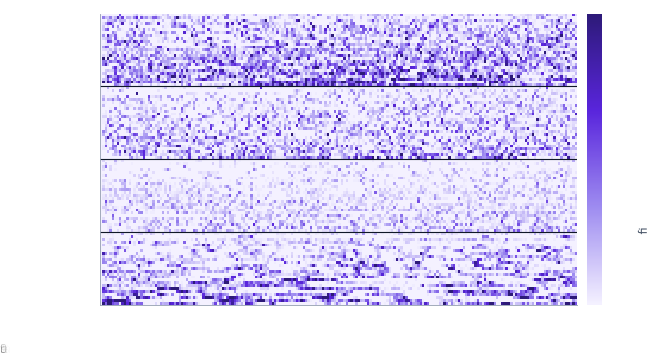

In [26]:
Y, I, rachas, abs_no = [], [], [], {k: [0.0, 0] for k in range(4)}
por_paso = np.zeros(20_000)
crudas = {}
for r in seqs[seqs.split == 'valid'].itertuples():
    d = leer('valid', r.rg, ['t0', 't1', 'is_scored'])
    m = d.is_scored.to_numpy()
    y = d[['t0', 't1']].to_numpy()
    por_paso += m
    borde = np.diff(np.r_[0, m.astype(int), 0])
    rachas.append(np.flatnonzero(borde == -1) - np.flatnonzero(borde == 1))
    Y.append(y[m])
    I.append(np.full(m.sum(), r.inst))
    abs_no[r.inst][0] += np.abs(y[~m]).sum()
    abs_no[r.inst][1] += 2 * (~m).sum()
    crudas[r.rg] = m
Y, I, rachas = np.vstack(Y), np.concatenate(I), np.concatenate(rachas)
pesos = np.abs(np.clip(Y, -2, 2))

mascara = {'filas': int(len(Y)), 'fraccion': len(Y) / (seqs.split.eq('valid').sum() * 20_000),
           'rachas': int(len(rachas)), 'racha_mediana': float(np.median(rachas)), 'racha_media': float(rachas.mean()), 'racha_p99': float(np.percentile(rachas, 99)), 'racha_max': int(rachas.max()),
           'filas_en_rachas_20': float(rachas[rachas >= 20].sum() / rachas.sum()), 'rachas_de_1': float((rachas == 1).mean()),
           'primer_paso': int(np.flatnonzero(por_paso)[0]), 'por_cuarto': [float(por_paso[i:i + 5000].mean()) for i in range(0, 20_000, 5000)]}
display(pd.Series(mascara).to_frame('valor').T)

por_inst = pd.DataFrame({
    'filas_%': pd.Series(I).value_counts(normalize=True).sort_index(),
    'peso_t0_%': [pesos[I == k, 0].sum() / pesos[:, 0].sum() for k in range(4)],
    'peso_t1_%': [pesos[I == k, 1].sum() / pesos[:, 1].sum() for k in range(4)],
    'abs_y_puntuadas': [np.abs(Y[I == k]).mean() for k in range(4)],
    'abs_y_resto': [abs_no[k][0] / abs_no[k][1] for k in range(4)],
    'puntuadas_%': seqs.groupby('inst').puntuadas.mean(),
})
display(por_inst)

bandas = pd.cut(pesos.ravel(), [-1, 0, .5, 1, 1.5, 2.0001], labels=['0', '(0, 0,5]', '(0,5, 1]', '(1, 1,5]', '(1,5, 2]'])
banda = pd.DataFrame({'w': pesos.ravel(), 'banda': bandas}).groupby('banda', observed=True).w.agg(['size', 'sum'])
banda = pd.DataFrame({'filas': banda['size'] / banda['size'].sum(), 'peso': banda['sum'] / banda['sum'].sum()})
display(banda)

recorte = float((np.abs(Y) > 2).mean())
print(f'Filas recortadas a ±2: {recorte:.1%} · corr(t0, t1) en filas puntuadas: {np.corrcoef(Y[:, 0], Y[:, 1])[0, 1]:.3f}')
R['mascara'] = mascara
R['peso_inst'] = por_inst.reset_index(names='inst').to_dict('records')
R['peso_banda'] = banda.reset_index().astype({'banda': str}).to_dict('records')
R['recorte'], R['corr_puntuadas'] = recorte, float(np.corrcoef(Y[:, 0], Y[:, 1])[0, 1])

# Mapa de la máscara: cada fila es una secuencia, cada celda un tramo de 100 filas
elegidas = muestra[muestra.split == 'valid'].sort_values(['inst', 'puntuadas'])
mapa = np.vstack([crudas[r.rg].reshape(200, 100).mean(1) for r in elegidas.itertuples()])
fig, ax = plt.subplots(figsize=(7.2, 4.2))
im = ax.imshow(mapa, aspect='auto', cmap=SECUENCIAL, vmin=0, vmax=.6, interpolation='nearest', extent=(0, 20_000, len(elegidas), 0))
for k in range(1, 4):
    ax.axhline(k * N_POR_GRUPO, color=TINTA, lw=.9)
ax.set_yticks([N_POR_GRUPO * (k + .5) for k in range(4)], [f'Instrumento {k}' for k in range(4)])
ax.set_xlabel('step_in_seq')
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=.03, pad=.02, ticks=[0, .2, .4, .6])
cb.ax.set_yticklabels(['0 %', '20 %', '40 %', '60 %'], fontsize=10)
cb.outline.set_visible(False)
cb.set_label('filas puntuadas en el tramo', fontsize=10.5)
guardar(fig, 'mascara_mapa')
del crudas

**Lectura:**
- Solo puntúa cerca de **1 de cada 10 filas**, y **train no trae `is_scored`**.
- Las filas puntuadas vienen en rachas muy cortas, con grandes diferencias entre secuencias y entre instrumentos. El instrumento 2 casi no puntúa.
- En las filas puntuadas, el target es más grande que en el resto: la selección no es neutra.
- **El instrumento 3 se lleva casi la mitad del peso**, y es el más difícil.

`need_prediction` no sirve como pista: es verdadero en todas las filas desde la 99.

## 10. Train vs. valid: ¿el mismo mercado?

No del todo. Los instrumentos están en proporciones distintas y, dentro de cada uno, la dinámica cambia.

In [27]:
comparacion = seqs.groupby('split')[['t0_std', 't1_std', 't0_cero', 't0_cambia', 't1_cambia', 'corr_t0_t1', 't0_fuera']].mean().T
comparacion['valid / train'] = comparacion.valid / comparacion.train
display(comparacion)

por_i = seqs.groupby(['inst', 'split'])[['t0_std', 't0_cambia']].mean().unstack()
display(por_i)

actividad = perfil.groupby(['familia', 'inst', 'split'], sort=False).delta_abs.mean().unstack()
actividad['razon'] = actividad.valid / actividad.train
tabla_act = actividad.razon.unstack('inst')
display(tabla_act)

R['train_valid'] = {'global': {c: {i: float(comparacion.loc[i, c]) for i in comparacion.index} for c in comparacion.columns},
                    'por_inst': {int(k): {'std_train': float(por_i.loc[k, ('t0_std', 'train')]), 'std_valid': float(por_i.loc[k, ('t0_std', 'valid')]),
                                          'cambia_train': float(por_i.loc[k, ('t0_cambia', 'train')]), 'cambia_valid': float(por_i.loc[k, ('t0_cambia', 'valid')])} for k in range(4)},
                    'actividad': {f: {int(k): float(v) for k, v in tabla_act.loc[f].items()} for f in tabla_act.index}}

split,train,valid,valid / train
t0_std,0.940,0.838,0.891
t1_std,0.942,0.834,0.885
t0_cero,0.219,0.218,0.996
t0_cambia,0.076,0.103,1.355
t1_cambia,0.078,0.100,1.280
corr_t0_t1,-0.799,-0.764,0.957
t0_fuera,0.031,0.026,0.815


t0_std       t0_cambia      
split  train valid     train valid
inst                              
0      0.914 0.927     0.150 0.153
1      0.933 0.932     0.117 0.095
2      0.944 0.879     0.045 0.042
3      0.946 0.714     0.067 0.116

inst,0,1,2,3
familia,,,,
i0_p,1.151,0.816,0.976,2.153
i0_v,1.272,0.814,2.259,1.386
i0_dp,1.042,0.786,1.002,1.060
i0_dv,0.852,0.788,1.110,0.323
i1_p,0.974,0.907,1.372,1.138
i1_v,0.940,1.300,2.862,1.127
i1_dp,0.991,0.932,1.226,0.862
i1_dv,0.895,0.938,1.207,0.772
a,0.991,0.954,1.039,1.091


Valid cambia más seguido y tiene un target con menos desvío. En `EXPERIMENTS.md` hay una medición más fuerte: un LightGBM sobre resúmenes por secuencia separa train de valid con **AUC 0,995**. También hay una consecuencia concreta: si se repesa valid con la mezcla de instrumentos de train, el mismo ensamble baja de 0,686 a 0,641.

**Moraleja:** una mejora en valid no se traslada sola al leaderboard. Hay que mirar el puntaje **por instrumento**.

## Guardar todo

resultados.json: 37 bloques


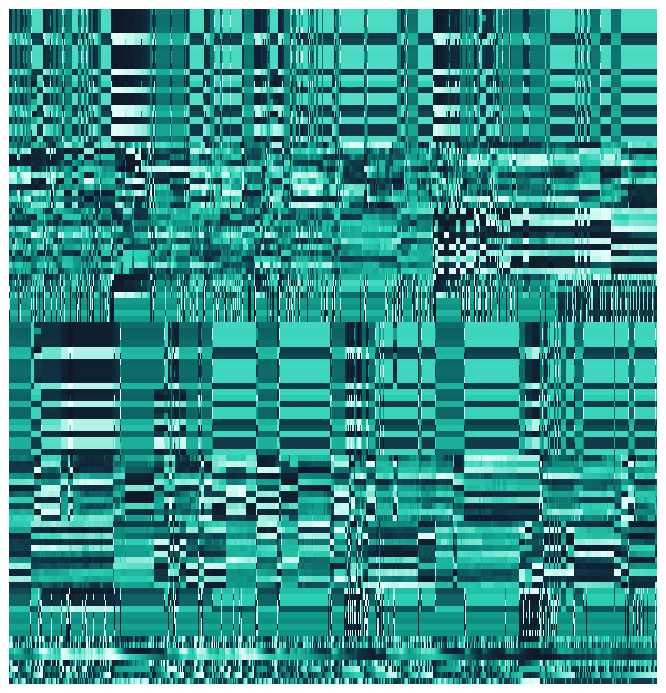

In [28]:
def a_json(v):
    if isinstance(v, (np.floating, np.integer)):
        return v.item()
    if isinstance(v, np.bool_):
        return bool(v)
    raise TypeError(type(v))


R['n_secuencias'] = {s: int(v) for s, v in seqs.split.value_counts().items()}
R['n_filas_total'] = int(len(seqs) * 20_000)
Path('resultados.json').write_text(json.dumps(R, indent=1, ensure_ascii=False, default=a_json), encoding='utf-8')
print('resultados.json:', len(R), 'bloques')

# La portada del deck: 112 columnas reales a lo largo de 1.200 filas
d = leer('valid', seqs[(seqs.split == 'valid') & (seqs.inst == 1)].iloc[8].rg, FEATURES).iloc[9_000:10_200]
rango = d.rank(pct=True).to_numpy().T
OSCURO = LinearSegmentedColormap.from_list('portada', ['#101828', '#0F3D4C', '#0E9384', '#2ED3B7', '#E6FFFA'])
fig = plt.figure(figsize=(7.2, 7.5))
ax = fig.add_axes([0, 0, 1, 1])
ax.imshow(rango, aspect='auto', cmap=OSCURO, interpolation='nearest')
ax.axis('off')
fig.savefig(FIG / 'portada.png', dpi=200, facecolor='#101828')
plt.show()